In [ ]:
import requests
import pandas as pd

#url = "https://pokeapi.co/api/v2/ability/"
#url = "https://pokeapi.co/api/v2/generation/1/"
#url = "https://pokeapi.co/api/v2/move/3/"
url = "https://pokeapi.co/api/v2/"
params = {
	"limit": 1351,
#	"offset": 0,
}

response = requests.get(url, params = params)
#response = requests.get(url)

response.json()

{'ability': 'https://pokeapi.co/api/v2/ability/',
 'berry': 'https://pokeapi.co/api/v2/berry/',
 'berry-firmness': 'https://pokeapi.co/api/v2/berry-firmness/',
 'berry-flavor': 'https://pokeapi.co/api/v2/berry-flavor/',
 'characteristic': 'https://pokeapi.co/api/v2/characteristic/',
 'contest-effect': 'https://pokeapi.co/api/v2/contest-effect/',
 'contest-type': 'https://pokeapi.co/api/v2/contest-type/',
 'currency': 'https://pokeapi.co/api/v2/currency/',
 'egg-group': 'https://pokeapi.co/api/v2/egg-group/',
 'encounter-condition': 'https://pokeapi.co/api/v2/encounter-condition/',
 'encounter-condition-value': 'https://pokeapi.co/api/v2/encounter-condition-value/',
 'encounter-method': 'https://pokeapi.co/api/v2/encounter-method/',
 'evolution-chain': 'https://pokeapi.co/api/v2/evolution-chain/',
 'evolution-trigger': 'https://pokeapi.co/api/v2/evolution-trigger/',
 'evolution-variable': 'https://pokeapi.co/api/v2/evolution-variable/',
 'gender': 'https://pokeapi.co/api/v2/gender/',
 '

In [11]:
import requests
import json

url = "https://pokeapi.co/api/v2/"

response = requests.get(url)
response.raise_for_status()

details = response.json()

# Display every field returned by the Pokémon endpoint
print(json.dumps(details, indent=2))

for key, value in details.items():
    print(key, ":", value)
    
print("Total endpoints:", len(details))

{
  "ability": "https://pokeapi.co/api/v2/ability/",
  "berry": "https://pokeapi.co/api/v2/berry/",
  "berry-firmness": "https://pokeapi.co/api/v2/berry-firmness/",
  "berry-flavor": "https://pokeapi.co/api/v2/berry-flavor/",
  "characteristic": "https://pokeapi.co/api/v2/characteristic/",
  "contest-effect": "https://pokeapi.co/api/v2/contest-effect/",
  "contest-type": "https://pokeapi.co/api/v2/contest-type/",
  "currency": "https://pokeapi.co/api/v2/currency/",
  "egg-group": "https://pokeapi.co/api/v2/egg-group/",
  "encounter-condition": "https://pokeapi.co/api/v2/encounter-condition/",
  "encounter-condition-value": "https://pokeapi.co/api/v2/encounter-condition-value/",
  "encounter-method": "https://pokeapi.co/api/v2/encounter-method/",
  "evolution-chain": "https://pokeapi.co/api/v2/evolution-chain/",
  "evolution-trigger": "https://pokeapi.co/api/v2/evolution-trigger/",
  "evolution-variable": "https://pokeapi.co/api/v2/evolution-variable/",
  "gender": "https://pokeapi.co/a

In [ ]:
import requests
import pandas as pd

base_url = "https://pokeapi.co/api/v2/"

# 1. Get the Pokémon endpoint from the API root
response = requests.get(base_url)
response.raise_for_status()
api_data = response.json()

# 2. Retrieve the first 50 Pokémon
response = requests.get(
    api_data["pokemon"],
    params={"limit": 50, "offset": 0}
)
response.raise_for_status()
pokemon_list = response.json()["results"]

# 3. Retrieve the details for each Pokémon
pokemon_data = []

for pokemon in pokemon_list:
    response = requests.get(pokemon["url"])
    response.raise_for_status()
    details = response.json()

    pokemon_data.append({
        "id": details["id"],
        "name": details["name"],
        "height": details["height"],
        "weight": details["weight"],
        "base_experience": details["base_experience"],
        "type_1": details["types"][0]["type"]["name"],
        "type_2": (
            details["types"][1]["type"]["name"]
            if len(details["types"]) > 1 else None
        ),
        "hp": details["stats"][0]["base_stat"],
        "attack": details["stats"][1]["base_stat"],
        "defense": details["stats"][2]["base_stat"],
        "special_attack": details["stats"][3]["base_stat"],
        "special_defense": details["stats"][4]["base_stat"],
        "speed": details["stats"][5]["base_stat"],
        "ability_1": details["abilities"][0]["ability"]["name"],
        "ability_2": (
            details["abilities"][1]["ability"]["name"]
            if len(details["abilities"]) > 1 else None
        )
    })

# 4. Create the DataFrame
df = pd.DataFrame(pokemon_data)

# 5. Display all 50 Pokémon and all columns
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.to_string(index=False))

# 6. Save the dataset
df.to_csv("pokemon_50.csv", index=False)
df.to_json("pokemon_50.json", orient="records", indent=2)

print("\nDataset shape:", df.shape)

 id       name  height  weight  base_experience   type_1 type_2  hp  attack  defense  special_attack  special_defense  speed     ability_1     ability_2
  1  bulbasaur       7      69               64    grass poison  45      49       49              65               65     45      overgrow   chlorophyll
  2    ivysaur      10     130              142    grass poison  60      62       63              80               80     60      overgrow   chlorophyll
  3   venusaur      20    1000              236    grass poison  80      82       83             100              100     80      overgrow   chlorophyll
  4 charmander       6      85               62     fire   None  39      52       43              60               50     65         blaze   solar-power
  5 charmeleon      11     190              142     fire   None  58      64       58              80               65     80         blaze   solar-power
  6  charizard      17     905              240     fire flying  78      84       

In [2]:

import requests
import pandas as pd
import time
import json
import random
from pathlib import Path

# ============================================================
# 1. SETTINGS
# ============================================================

BASE_URL = "https://pokeapi.co/api/v2/"
TARGET_COUNT = None
LIST_LIMIT = 2000
REQUEST_DELAY = 1.0
RANDOM_SEED = 42

CACHE_DIR = Path("pokemon_cache")
CACHE_DIR.mkdir(exist_ok=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "PokemonDataLearningProject/1.0"
})

# ============================================================
# 2. FUNCTION TO RETRIEVE API DATA WITH CACHING
# ============================================================

def get_json(url, params=None, cache_file=None):

    cache_path = CACHE_DIR / cache_file if cache_file else None

    # Reuse previously downloaded data
    if cache_path and cache_path.exists():
        with cache_path.open("r", encoding="utf-8") as file:
            return json.load(file)

    # Be considerate of the public API
    time.sleep(REQUEST_DELAY)

    response = session.get(
        url,
        params=params,
        timeout=30
    )

    # Skip resources that do not exist
    if response.status_code == 404:
        print(f"404 - Skipping missing resource: {url}")
        return None

    # Raise errors for other unsuccessful responses
    response.raise_for_status()

    data = response.json()

    # Save successful responses to cache
    if cache_path:
        with cache_path.open("w", encoding="utf-8") as file:
            json.dump(data, file)

    return data


# ============================================================
# 3. GET THE API ENDPOINTS
# ============================================================

api_data = get_json(
    BASE_URL,
    cache_file="api_root.json"
)

if api_data is None:
    raise RuntimeError("Could not retrieve the PokéAPI endpoints.")

print("PokéAPI connected successfully.")


# ============================================================
# 4. RETRIEVE FULL LIST OF AVAILABLE POKÉMON
# ============================================================

all_pokemon = []
offset = 0

while True:
    pokemon_page = get_json(
        api_data["pokemon"],
        params={
            "limit": LIST_LIMIT,
            "offset": offset
        },
        cache_file=f"pokemon_list_{offset}_{LIST_LIMIT}.json"
    )

    if pokemon_page is None:
        raise RuntimeError(
            f"Could not retrieve Pokémon list at offset {offset}."
        )

    results = pokemon_page["results"]
    all_pokemon.extend(results)

    print(
        f"Retrieved {len(all_pokemon)} "
        f"of {pokemon_page['count']} Pokémon entries"
    )

    # Stop when the API has no more pages.
    if pokemon_page["next"] is None:
        break

    offset += LIST_LIMIT

print("Total Pokémon entries retrieved:", len(all_pokemon))

# ============================================================
# 5. PREPARE DATA COLLECTION
# ============================================================
# Data Engineering: Preserve the original API order.
# Do not randomise the list during data ingestion.
# Random sampling can be performed later during EDA.

pokemon_data = []
raw_pokemon_data = []

# ============================================================
# 6. RETRIEVE POKÉMON DETAILS AND SPECIES INFORMATION
# ============================================================

for pokemon in all_pokemon:


    pokemon_id = pokemon["url"].rstrip("/").split("/")[-1]

    # --------------------------------------------------------
    # Get Pokémon details
    # --------------------------------------------------------

    details = get_json(
        pokemon["url"],
        cache_file=f"pokemon_{pokemon_id}.json"
    )

    if details is None:
        continue

    # --------------------------------------------------------
    # Get species details
    # --------------------------------------------------------

    species_url = details["species"]["url"]
    species_id = species_url.rstrip("/").split("/")[-1]

    species = get_json(
        species_url,
        cache_file=f"species_{species_id}.json"
    )

    if species is None:
        continue

    # --------------------------------------------------------
    # Extract base stats safely
    # --------------------------------------------------------

    stats = {
        stat["stat"]["name"]: stat["base_stat"]
        for stat in details["stats"]
    }

    types = [
        item["type"]["name"]
        for item in details["types"]
    ]

    abilities = [
        item["ability"]["name"]
        for item in details["abilities"]
    ]

    moves = [
        item["move"]["name"]
        for item in details["moves"]
    ]

    forms = [
        item["name"]
        for item in details["forms"]
    ]

    egg_groups = [
        item["name"]
        for item in species["egg_groups"]
    ]

    # --------------------------------------------------------
    # Build one row per Pokémon
    # --------------------------------------------------------

    row = {
        # Identification
        "id": details["id"],
        "name": details["name"],
        "species": species["name"],
        "order": details["order"],
        "is_default": details["is_default"],

        # Physical characteristics
        "height": details["height"],
        "weight": details["weight"],
        "weight_category": (
            "heavy" if details["weight"] >= 1000 else "light"
        ),

        # Experience and species characteristics
        "base_experience": details["base_experience"],
        "color": species["color"]["name"],
        "shape": (
            species["shape"]["name"]
            if species["shape"] else None
        ),
        "habitat": (
            species["habitat"]["name"]
            if species["habitat"] else None
        ),
        "growth_rate": species["growth_rate"]["name"],
        "capture_rate": species["capture_rate"],
        "base_happiness": species["base_happiness"],
        "generation": species["generation"]["name"],

        # Pokémon types
        "type_1": types[0] if len(types) > 0 else None,
        "type_2": types[1] if len(types) > 1 else None,
        "types_count": len(types),
        "types": types,

        # Abilities
        "ability_1": abilities[0] if len(abilities) > 0 else None,
        "ability_2": abilities[1] if len(abilities) > 1 else None,
        "abilities_count": len(abilities),
        "abilities": abilities,

        # Base stats
        "hp": stats.get("hp"),
        "attack": stats.get("attack"),
        "defense": stats.get("defense"),
        "special_attack": stats.get("special-attack"),
        "special_defense": stats.get("special-defense"),
        "speed": stats.get("speed"),
        "total_stats": sum(stats.values()),

        # Moves and forms
        "moves_count": len(moves),
        "moves": moves,
        "forms_count": len(forms),
        "forms": forms,

        # Species classifications
        "is_baby": species["is_baby"],
        "is_legendary": species["is_legendary"],
        "is_mythical": species["is_mythical"],

        # Egg and breeding information
        "egg_group_1": (
            egg_groups[0] if len(egg_groups) > 0 else None
        ),
        "egg_group_2": (
            egg_groups[1] if len(egg_groups) > 1 else None
        ),
        "gender_rate": species["gender_rate"],
        "hatch_counter": species["hatch_counter"],
        "has_gender_differences": species["has_gender_differences"],

        # Sprites
        "front_default_sprite": details["sprites"]["front_default"],
        "back_default_sprite": details["sprites"]["back_default"],
        "front_shiny_sprite": details["sprites"]["front_shiny"],
        "back_shiny_sprite": details["sprites"]["back_shiny"],

        # Other API fields
        "game_indices_count": len(details["game_indices"]),
        "held_items_count": len(details["held_items"]),
        "past_types_count": len(details["past_types"]),
        "location_area_encounters": details["location_area_encounters"],
        "cries_latest": details["cries"].get("latest"),
        "cries_legacy": details["cries"].get("legacy")
    }

    pokemon_data.append(row)

    # Preserve raw API responses for later analysis
    raw_pokemon_data.append({
        "pokemon": details,
        "species": species
    })

    processed = len(pokemon_data)

    if processed % 100 == 0:
        print(f"Successfully processed {processed} Pokémon")


# ============================================================
# 7. CREATE THE DATAFRAME
# ============================================================

df = pd.DataFrame(pokemon_data)

print("\nData collection finished.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())


# ============================================================
# 8. CHECK DATA QUALITY
# ============================================================

print("\nDataFrame information:")
df.info()

print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate Pokémon IDs:", df["id"].duplicated().sum())


# ============================================================
# 9. SAVE CSV AND JSON FILES
# ============================================================

csv_file = "pokemon_full.csv"
json_file = "pokemon_full.json"
raw_json_file = "pokemon_full_raw.json"

df.to_csv(
    csv_file,
    index=False,
    encoding="utf-8"
)

df.to_json(
    json_file,
    orient="records",
    indent=2,
    force_ascii=False
)

with open(raw_json_file, "w", encoding="utf-8") as file:
    json.dump(
        raw_pokemon_data,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nFiles saved successfully:")
print(csv_file)
print(json_file)
print(raw_json_file)

if len(df) < TARGET_COUNT:
    print(
        f"\nWarning: Only {len(df)} valid Pokémon were collected. "
        "Check the messages above for missing resources or errors."
    )
else:
    print(f"\nSuccess: Collected {TARGET_COUNT} valid Pokémon.")


PokéAPI connected successfully.
Retrieved 1351 of 1351 Pokémon entries
Total Pokémon entries retrieved: 1351
Successfully processed 100 Pokémon
Successfully processed 200 Pokémon
Successfully processed 300 Pokémon
Successfully processed 400 Pokémon
Successfully processed 500 Pokémon
Successfully processed 600 Pokémon
Successfully processed 700 Pokémon
Successfully processed 800 Pokémon
Successfully processed 900 Pokémon
Successfully processed 1000 Pokémon
Successfully processed 1100 Pokémon
Successfully processed 1200 Pokémon
Successfully processed 1300 Pokémon

Data collection finished.
Rows: 1351
Columns: 53


,id,name,species,order,is_default,height,weight,weight_category,base_experience,color,...,front_default_sprite,back_default_sprite,front_shiny_sprite,back_shiny_sprite,game_indices_count,held_items_count,past_types_count,location_area_encounters,cries_latest,cries_legacy
0,1,bulbasaur,bulbasaur,1,True,7,69,light,64.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/1/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
1,2,ivysaur,ivysaur,2,True,10,130,light,142.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/2/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
2,3,venusaur,venusaur,3,True,20,1000,heavy,236.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/3/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
3,4,charmander,charmander,5,True,6,85,light,62.0,red,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/4/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
4,5,charmeleon,charmeleon,6,True,11,190,light,142.0,red,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/5/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 53 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        1351 non-null   int64  
 1   name                      1351 non-null   object 
 2   species                   1351 non-null   object 
 3   order                     1351 non-null   int64  
 4   is_default                1351 non-null   bool   
 5   height                    1351 non-null   int64  
 6   weight                    1351 non-null   int64  
 7   weight_category           1351 non-null   object 
 8   base_experience           1302 non-null   float64
 9   color                     1351 non-null   object 
 10  shape                     1351 non-null   object 
 11  habitat                   520 non-null    object 
 12  growth_rate               1351 non-null   object 
 13  capture_rate              1351 non-null

TypeError: '<' not supported between instances of 'int' and 'NoneType'

Rayquaza Mega | Attack: 180 | Special Attack: 180 | Combined: 360


Deoxys Attack | Attack: 180 | Special Attack: 180 | Combined: 360


Mewtwo Mega Y | Attack: 150 | Special Attack: 194 | Combined: 344


Mewtwo Mega X | Attack: 190 | Special Attack: 154 | Combined: 344


Necrozma Ultra | Attack: 167 | Special Attack: 167 | Combined: 334


Groudon Primal | Attack: 180 | Special Attack: 150 | Combined: 330


Hoopa Unbound | Attack: 160 | Special Attack: 170 | Combined: 330


Kyogre Primal | Attack: 150 | Special Attack: 180 | Combined: 330


Diancie Mega | Attack: 160 | Special Attack: 160 | Combined: 320


Zeraora Mega | Attack: 157 | Special Attack: 147 | Combined: 304


,name,attack,special_attack,offensive_score
0,rayquaza-mega,180,180,360
1,deoxys-attack,180,180,360
2,mewtwo-mega-y,150,194,344
3,mewtwo-mega-x,190,154,344
4,necrozma-ultra,167,167,334
5,groudon-primal,180,150,330
6,hoopa-unbound,160,170,330
7,kyogre-primal,150,180,330
8,diancie-mega,160,160,320
9,zeraora-mega,157,147,304


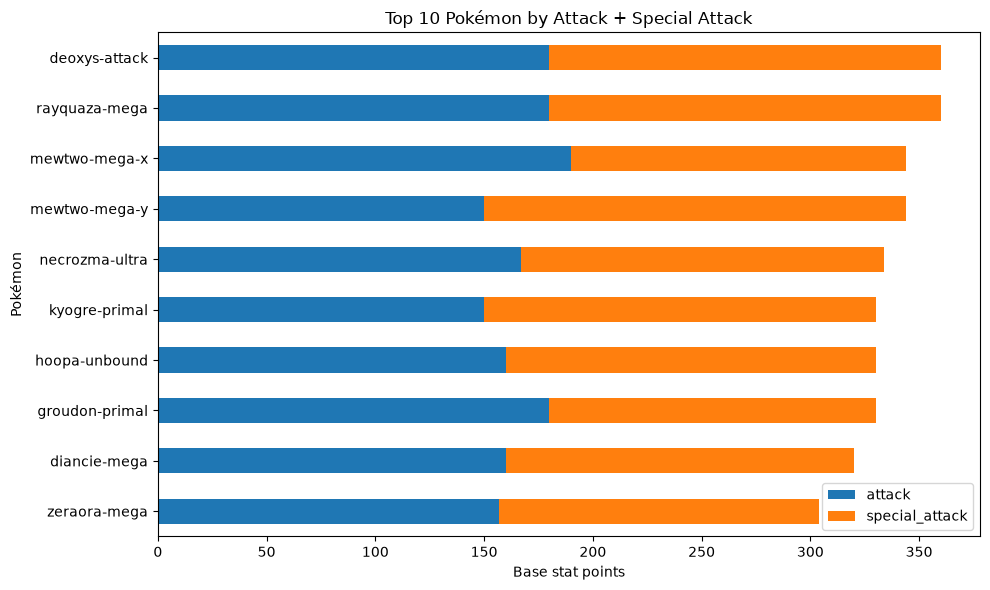

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Data Engineering: Load the full dataset exported from your API pipeline.
df = pd.read_csv("pokemon_full.csv")

# EDA: Ensure the stats are numeric before performing calculations.
df["attack"] = pd.to_numeric(df["attack"], errors="coerce")
df["special_attack"] = pd.to_numeric(
    df["special_attack"], errors="coerce"
)

# EDA: Create a combined offensive score.
df["offensive_score"] = df["attack"] + df["special_attack"]

# EDA: Rank the top 10 records by offensive base stats.
top10 = (
    df.dropna(subset=["attack", "special_attack"])
      .sort_values("offensive_score", ascending=False)
      .head(10)
      .copy()
)

# Visualisation: Display Pokémon images, names and their scores.
for _, row in top10.iterrows():
    name = row["name"].replace("-", " ").title()
    url = row.get("front_default_sprite")

    print(
        f"{name} | Attack: {row['attack']:.0f} | "
        f"Special Attack: {row['special_attack']:.0f} | "
        f"Combined: {row['offensive_score']:.0f}"
    )

    if pd.notna(url) and str(url).startswith("https://"):
        display(HTML(
            f'<div style="display:inline-block;text-align:center;'
            f'margin:8px;padding:8px;border:1px solid #ccc;'
            f'border-radius:8px;width:140px">'
            f'<img src="{url}" width="100" height="100" '
            f'style="object-fit:contain"><br>'
            f'<b>{name}</b><br>'
            f'Offensive score: {row["offensive_score"]:.0f}'
            f'</div>'
        ))

# EDA: Compare the two stats and the combined score.
display(
    top10[[
        "name", "attack", "special_attack", "offensive_score"
    ]].reset_index(drop=True)
)

top10.sort_values("offensive_score").plot.barh(
    x="name",
    y=["attack", "special_attack"],
    stacked=True,
    figsize=(10, 6),
    title="Top 10 Pokémon by Attack + Special Attack"
)

plt.xlabel("Base stat points")
plt.ylabel("Pokémon")
plt.tight_layout()
plt.show()


Dataset shape: (1351, 53)

First five records:


,id,name,species,order,is_default,height,weight,weight_category,base_experience,color,...,front_default_sprite,back_default_sprite,front_shiny_sprite,back_shiny_sprite,game_indices_count,held_items_count,past_types_count,location_area_encounters,cries_latest,cries_legacy
0,1,bulbasaur,bulbasaur,1,True,7,69,light,64.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/1/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
1,2,ivysaur,ivysaur,2,True,10,130,light,142.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/2/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
2,3,venusaur,venusaur,3,True,20,1000,heavy,236.0,green,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/3/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
3,4,charmander,charmander,5,True,6,85,light,62.0,red,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/4/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...
4,5,charmeleon,charmeleon,6,True,11,190,light,142.0,red,...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,46,0,0,https://pokeapi.co/api/v2/pokemon/5/encounters,https://raw.githubusercontent.com/PokeAPI/crie...,https://raw.githubusercontent.com/PokeAPI/crie...



Column data types:
id                            int64
name                         object
species                      object
order                         int64
is_default                     bool
height                        int64
weight                        int64
weight_category              object
base_experience             float64
color                        object
shape                        object
habitat                      object
growth_rate                  object
capture_rate                  int64
base_happiness                int64
generation                   object
type_1                       object
type_2                       object
types_count                   int64
types                        object
ability_1                    object
ability_2                    object
abilities_count               int64
abilities                    object
hp                            int64
attack                        int64
defense                       int64
special_

,missing_count
egg_group_2,984
habitat,831
cries_legacy,678
type_2,586
ability_2,363
base_experience,49
back_shiny_sprite,9
back_default_sprite,9
front_default_sprite,9
ability_1,9


Duplicate IDs: 0
Duplicate names: 0

Base-stat summary:


,hp,attack,defense,special_attack,special_defense,speed
count,1351.00,1351.00,1351.00,1351.00,1351.00,1351.00
mean,71.67,82.76,76.19,75.42,74.12,72.00
std,26.83,32.35,30.71,34.03,27.80,30.64
min,1.00,5.00,5.00,10.00,20.00,5.00
25%,55.00,60.00,55.00,50.00,54.00,49.00
50%,70.00,80.00,70.00,69.00,70.00,70.00
75%,85.00,102.50,95.00,97.00,90.00,95.00
max,255.00,190.00,250.00,216.00,250.00,200.00



Average base stats:


,average
attack,82.76
defense,76.19
special_attack,75.42
special_defense,74.12
speed,72.00
hp,71.67


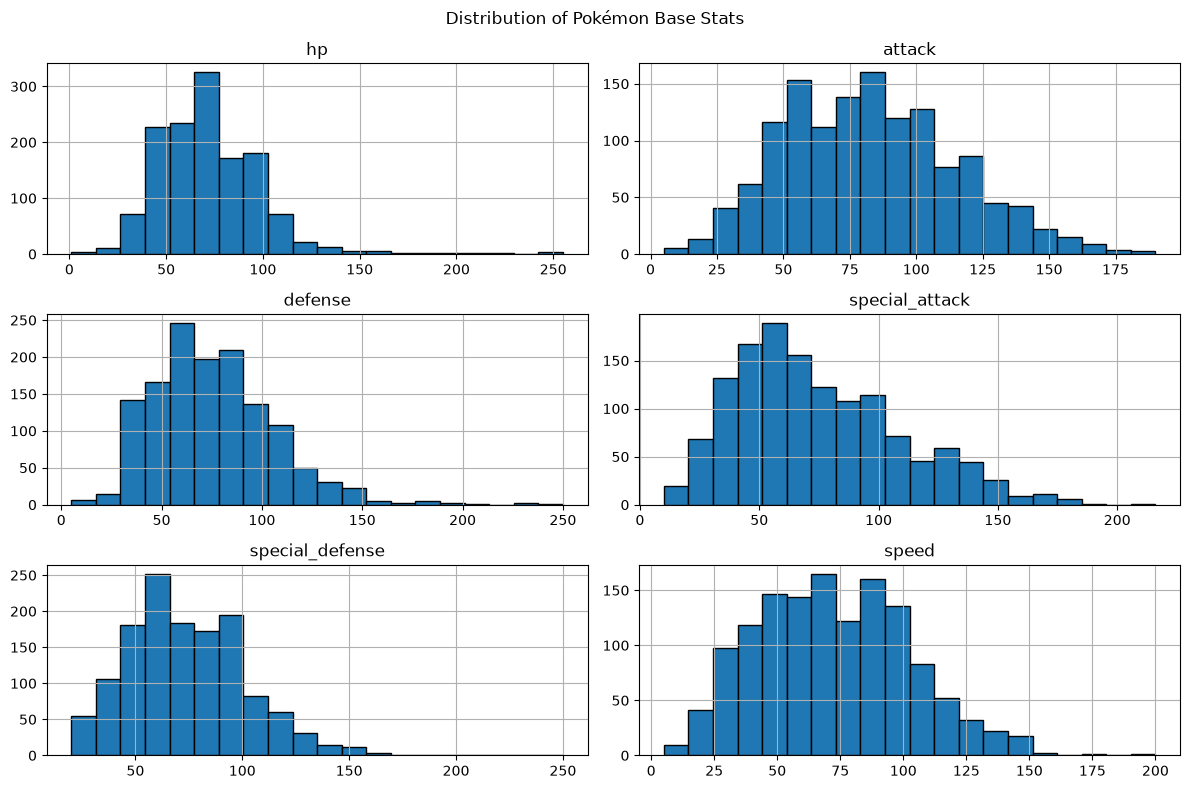

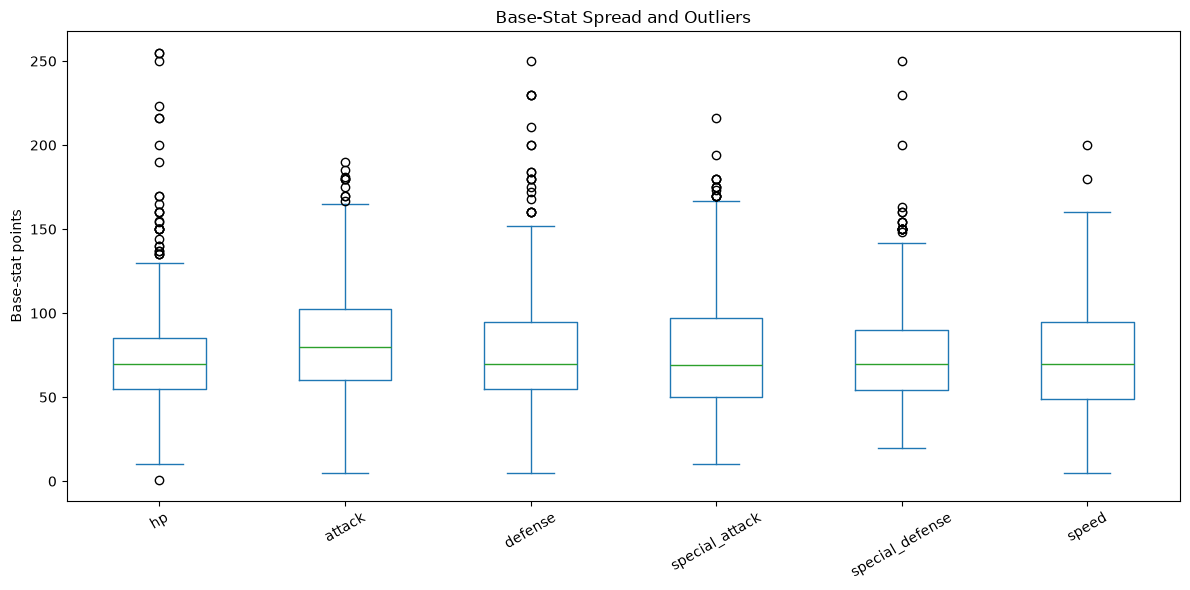


Correlation matrix:


,hp,attack,defense,special_attack,special_defense,speed
hp,1.00,0.46,0.34,0.36,0.39,0.16
attack,0.46,1.00,0.48,0.31,0.28,0.36
defense,0.34,0.48,1.00,0.24,0.54,0.01
special_attack,0.36,0.31,0.24,1.00,0.52,0.42
special_defense,0.39,0.28,0.54,0.52,1.00,0.23
speed,0.16,0.36,0.01,0.42,0.23,1.00


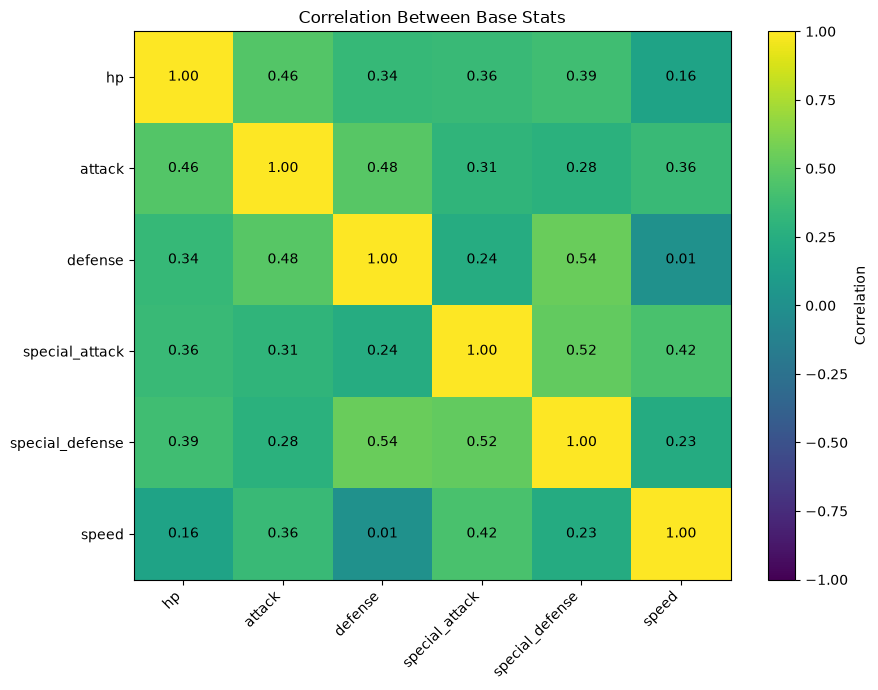


Top 10 by total base stats:


,name,hp,attack,defense,special_attack,special_defense,speed,total_base_stats
0,eternatus-eternamax,255,115,250,125,250,130,1125
1,mewtwo-mega-x,106,190,100,154,100,130,780
2,mewtwo-mega-y,106,150,70,194,120,140,780
3,rayquaza-mega,105,180,100,180,100,115,780
4,zygarde-mega,216,70,91,216,85,100,778
5,kyogre-primal,100,150,90,180,160,90,770
6,groudon-primal,100,180,160,150,90,90,770
7,necrozma-ultra,97,167,97,167,97,129,754
8,arceus,120,120,120,120,120,120,720
9,zygarde-complete,216,100,121,91,95,85,708


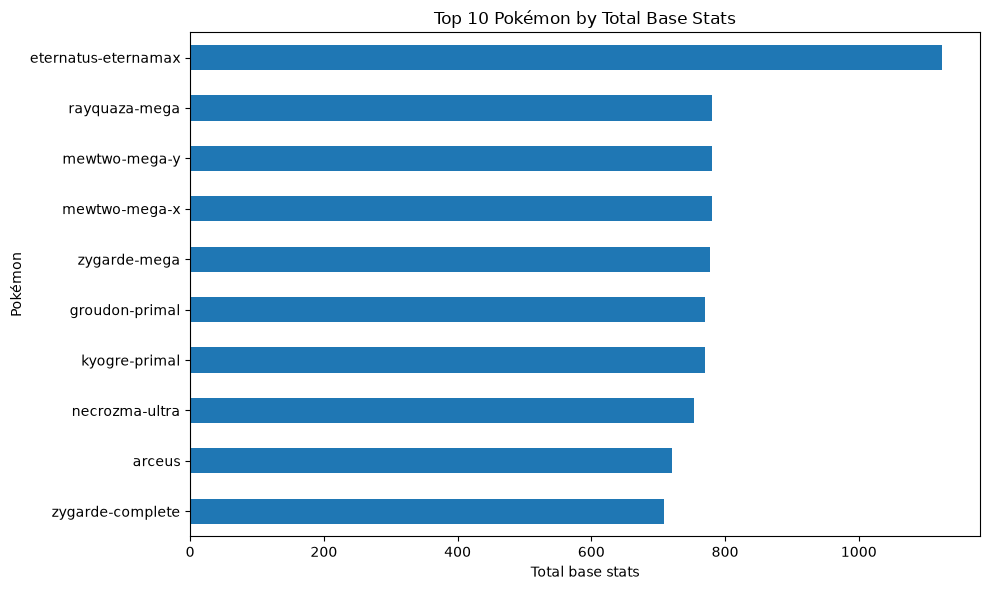


Top 10 by Hp:


,name,hp
0,wailord,170
1,cetitan,170
2,wobbuffet,190
3,regidrago,200
4,zygarde-complete,216
5,zygarde-mega,216
6,guzzlord,223
7,chansey,250
8,blissey,255
9,eternatus-eternamax,255


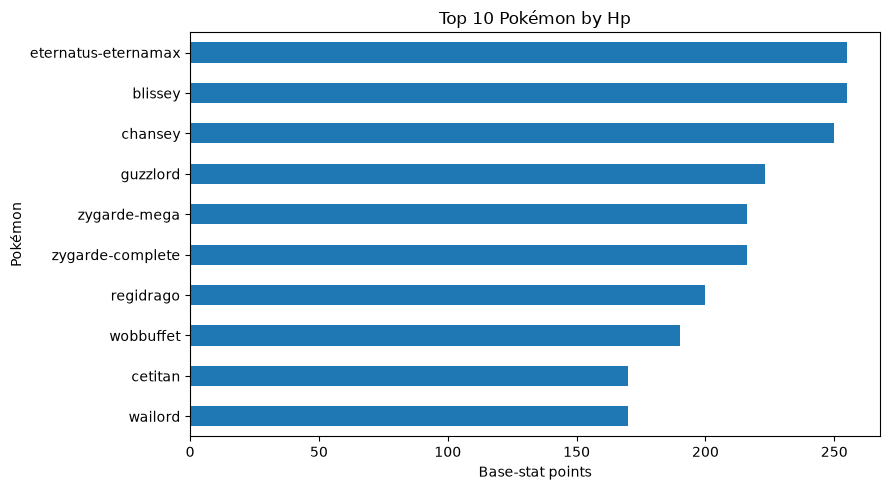


Top 10 by Attack:


,name,attack
0,necrozma-ultra,167
1,kyurem-black,170
2,garchomp-mega,170
3,baxcalibur-mega,175
4,deoxys-attack,180
5,groudon-primal,180
6,rayquaza-mega,180
7,kartana,181
8,heracross-mega,185
9,mewtwo-mega-x,190


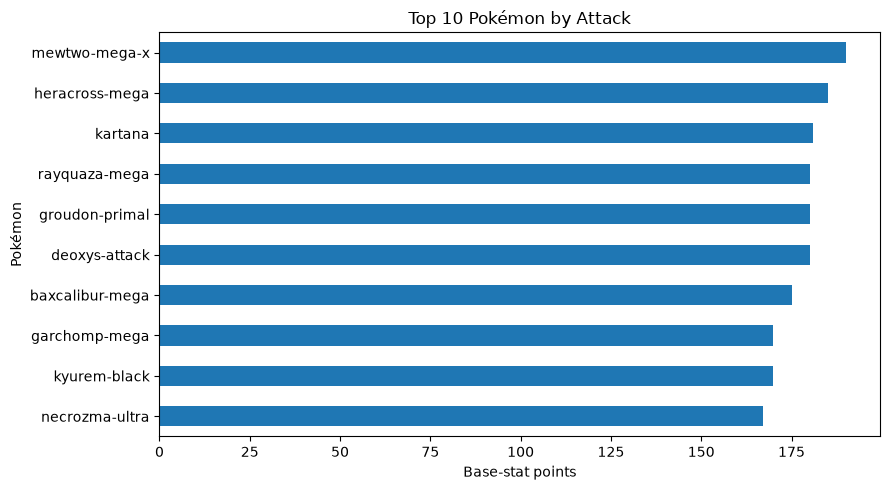


Top 10 by Defense:


,name,defense
0,cloyster,180
1,avalugg,184
2,avalugg-hisui,184
3,steelix,200
4,regirock,200
5,stakataka,211
6,shuckle,230
7,aggron-mega,230
8,steelix-mega,230
9,eternatus-eternamax,250


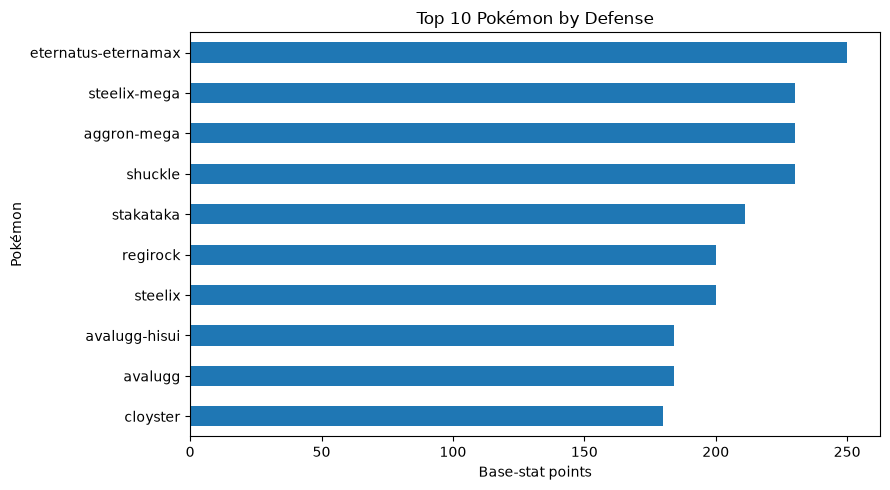


Top 10 by Special Attack:


,name,special_attack
0,kyurem-white,170
1,xurkitree,173
2,alakazam-mega,175
3,chandelure-mega,175
4,heatran-mega,175
5,deoxys-attack,180
6,kyogre-primal,180
7,rayquaza-mega,180
8,mewtwo-mega-y,194
9,zygarde-mega,216


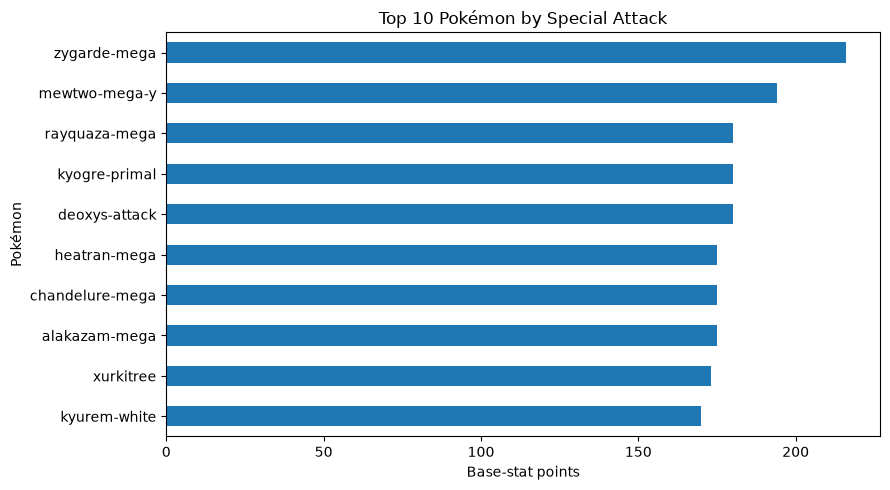


Top 10 by Special Defense:


,name,special_defense
0,registeel,150
1,lugia,154
2,ho-oh,154
3,florges,154
4,deoxys-defense,160
5,kyogre-primal,160
6,dragalge-mega,163
7,regice,200
8,shuckle,230
9,eternatus-eternamax,250


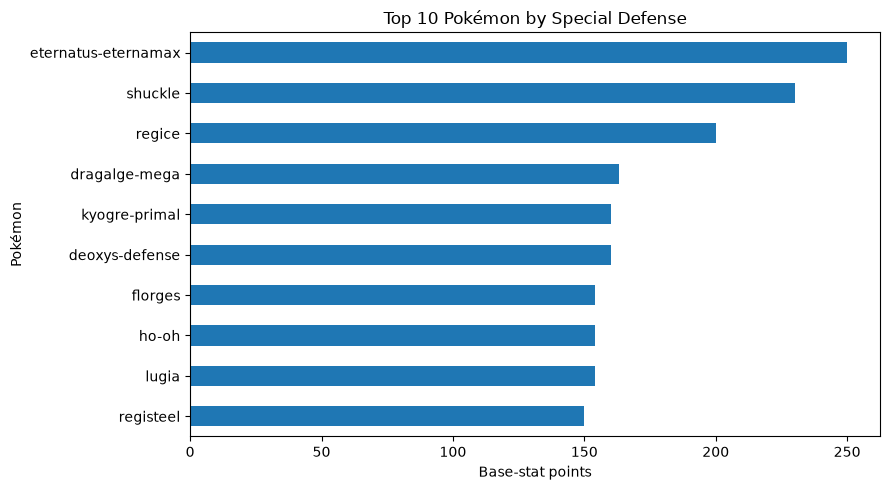


Top 10 by Speed:


,name,speed
0,electrode,150
1,deoxys-normal,150
2,pheromosa,151
3,absol-mega-z,151
4,garchomp-mega-z,151
5,lucario-mega-z,151
6,zeraora-mega,153
7,ninjask,160
8,deoxys-speed,180
9,regieleki,200


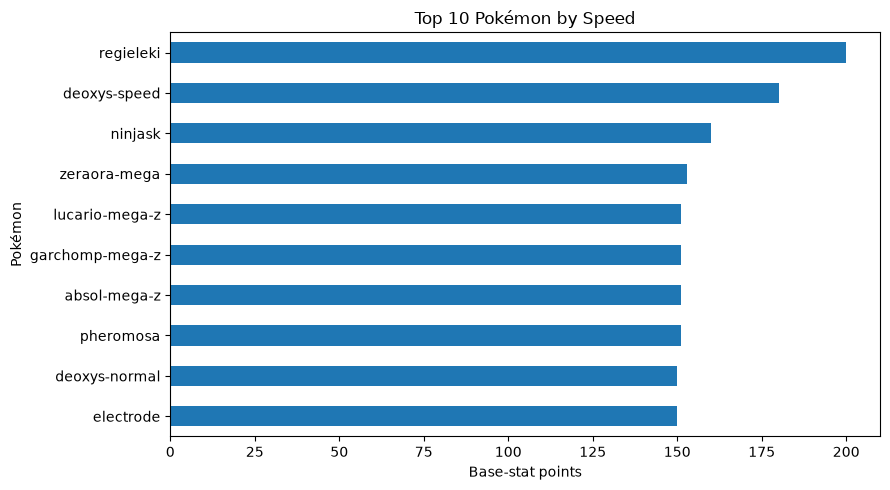

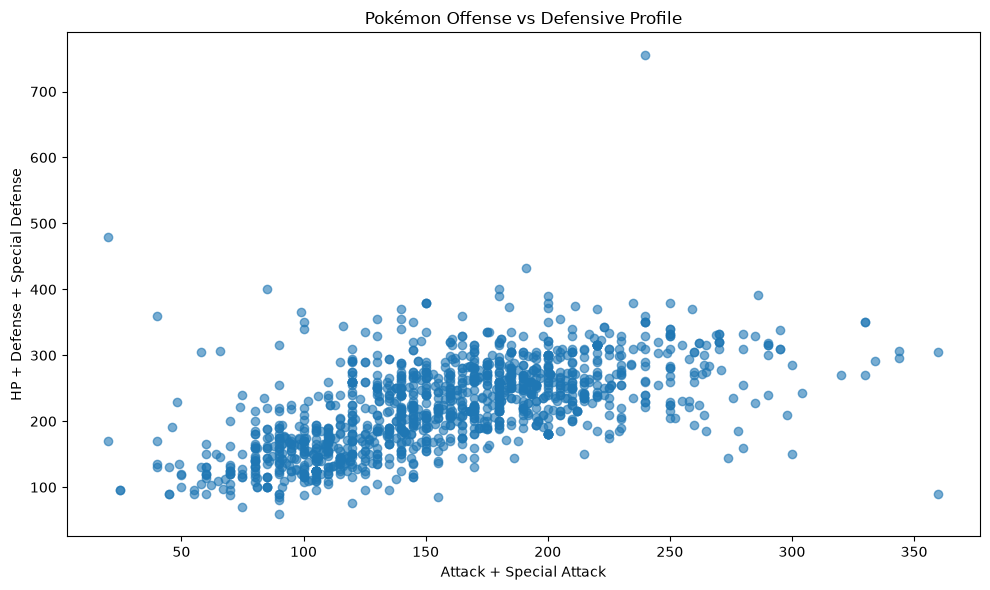


Average stats by is_legendary:


,hp,attack,defense,special_attack,special_defense,speed,total_base_stats
is_legendary,,,,,,,
False,69.00,80.05,73.83,72.15,71.28,69.26,435.57
True,99.08,110.52,100.46,108.98,103.18,100.12,622.34



Average stats by is_mythical:


,hp,attack,defense,special_attack,special_defense,speed,total_base_stats
is_mythical,,,,,,,
False,71.29,81.93,75.53,74.26,73.47,71.22,447.70
True,85.08,111.32,99.16,115.53,96.26,98.97,606.32



Top 10 Pokémon by total base stats — images:



EDA complete.
Analysis records: 1351
Analysis columns: 58
Saved: pokemon_base_stats_eda.csv


In [4]:

# ============================================================
# POKEMON BASE-STAT EDA
# Data Engineering + Exploratory Data Analysis
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. DATA INGESTION
# Data Engineering: Load the dataset into a DataFrame.
# ------------------------------------------------------------

df = pd.read_csv("pokemon_full.csv")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

# ------------------------------------------------------------
# 2. DATA QUALITY CHECKS
# Data Engineering: Check missing values, duplicates and types.
# ------------------------------------------------------------

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

if "id" in df.columns:
    print("Duplicate IDs:", df["id"].duplicated().sum())

if "name" in df.columns:
    print("Duplicate names:", df["name"].duplicated().sum())

# ------------------------------------------------------------
# 3. PREPARE THE SIX BASE STATS
# Data Engineering: Convert stat columns to numeric values.
# ------------------------------------------------------------

stats = [
    "hp",
    "attack",
    "defense",
    "special_attack",
    "special_defense",
    "speed"
]

missing_columns = [col for col in stats if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing required stat columns: {missing_columns}"
    )

for col in stats:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# EDA: Use records with all six stats for fair comparisons.
analysis_df = df.dropna(subset=stats).copy()

# ------------------------------------------------------------
# 4. FEATURE ENGINEERING
# Data Engineering / EDA: Create useful derived metrics.
# ------------------------------------------------------------

analysis_df["total_base_stats"] = analysis_df[stats].sum(axis=1)

analysis_df["offense"] = (
    analysis_df["attack"] + analysis_df["special_attack"]
)

analysis_df["defense_profile"] = (
    analysis_df["hp"]
    + analysis_df["defense"]
    + analysis_df["special_defense"]
)

analysis_df["physical_profile"] = (
    analysis_df["attack"] + analysis_df["defense"]
)

analysis_df["special_profile"] = (
    analysis_df["special_attack"]
    + analysis_df["special_defense"]
)

# ------------------------------------------------------------
# 5. DESCRIPTIVE STATISTICS
# EDA: Understand the distribution of each base stat.
# ------------------------------------------------------------

print("\nBase-stat summary:")
display(analysis_df[stats].describe().round(2))

print("\nAverage base stats:")
display(
    analysis_df[stats]
    .mean()
    .sort_values(ascending=False)
    .to_frame("average")
    .round(2)
)

# ------------------------------------------------------------
# 6. HISTOGRAMS
# EDA: Explore the distribution of each stat.
# ------------------------------------------------------------

analysis_df[stats].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Pokémon Base Stats")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. BOXPLOTS
# EDA: Compare spread and identify unusually high values.
# ------------------------------------------------------------

analysis_df[stats].plot(
    kind="box",
    subplots=False,
    figsize=(12, 6),
    rot=30
)

plt.title("Base-Stat Spread and Outliers")
plt.ylabel("Base-stat points")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CORRELATION MATRIX
# EDA: Explore which stats tend to increase together.
# Correlation does not prove causation.
# ------------------------------------------------------------

correlation = analysis_df[stats].corr()

print("\nCorrelation matrix:")
display(correlation.round(2))

plt.figure(figsize=(9, 7))

image = plt.imshow(
    correlation,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(image, label="Correlation")
plt.xticks(range(len(stats)), stats, rotation=45, ha="right")
plt.yticks(range(len(stats)), stats)

for i in range(len(stats)):
    for j in range(len(stats)):
        plt.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.title("Correlation Between Base Stats")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. TOP 10 BY TOTAL BASE STATS
# EDA: Identify records with the highest overall stat totals.
# ------------------------------------------------------------

top_total = analysis_df.nlargest(10, "total_base_stats")

print("\nTop 10 by total base stats:")
display(
    top_total[["name"] + stats + ["total_base_stats"]]
    .reset_index(drop=True)
)

top_total.sort_values("total_base_stats").plot.barh(
    x="name",
    y="total_base_stats",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 10 Pokémon by Total Base Stats")
plt.xlabel("Total base stats")
plt.ylabel("Pokémon")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. TOP 10 FOR EACH INDIVIDUAL STAT
# EDA: Find specialist Pokémon, not just all-rounders.
# ------------------------------------------------------------

for stat in stats:
    top = analysis_df.nlargest(10, stat).sort_values(stat)

    print(f"\nTop 10 by {stat.replace('_', ' ').title()}:")
    display(top[["name", stat]].reset_index(drop=True))

    top.plot.barh(
        x="name",
        y=stat,
        figsize=(9, 5),
        legend=False
    )

    plt.title(f"Top 10 Pokémon by {stat.replace('_', ' ').title()}")
    plt.xlabel("Base-stat points")
    plt.ylabel("Pokémon")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 11. OFFENSE VS DEFENSE
# EDA: Compare offensive power with a simple durability proxy.
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["offense"],
    analysis_df["defense_profile"],
    alpha=0.6
)

plt.xlabel("Attack + Special Attack")
plt.ylabel("HP + Defense + Special Defense")
plt.title("Pokémon Offense vs Defensive Profile")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. LEGENDARY / MYTHICAL COMPARISON
# EDA: Compare groups only if these fields are available.
# ------------------------------------------------------------

for flag in ["is_legendary", "is_mythical"]:
    if flag in analysis_df.columns:
        print(f"\nAverage stats by {flag}:")
        display(
            analysis_df.groupby(flag)[stats + ["total_base_stats"]]
            .mean()
            .round(2)
        )

# ------------------------------------------------------------
# 13. DISPLAY IMAGES FOR THE TOP 10
# Visualisation: Use stored URLs; no image download needed.
# ------------------------------------------------------------

sprite_col = "front_default_sprite"

if sprite_col in analysis_df.columns:
    print("\nTop 10 Pokémon by total base stats — images:")

    for _, row in top_total.iterrows():
        name = str(row["name"]).replace("-", " ").title()
        url = row.get(sprite_col)

        if pd.notna(url) and str(url).startswith("https://"):
            display(HTML(
                f'<div style="display:inline-block;'
                f'text-align:center;margin:8px;padding:8px;'
                f'border:1px solid #ccc;border-radius:8px;'
                f'width:140px">'
                f'<img src="{url}" width="100" height="100" '
                f'style="object-fit:contain"><br>'
                f'<b>{name}</b><br>'
                f'Total stats: {row["total_base_stats"]:.0f}'
                f'</div>'
            ))

# ------------------------------------------------------------
# 14. EXPORT THE ANALYSIS DATA
# Data Engineering: Save the enriched dataset separately.
# Preserve the original raw dataset.
# ------------------------------------------------------------

analysis_df.to_csv("pokemon_base_stats_eda.csv", index=False)

print("\nEDA complete.")
print("Analysis records:", len(analysis_df))
print("Analysis columns:", len(analysis_df.columns))
print("Saved: pokemon_base_stats_eda.csv")
